<a href="https://www.kaggle.com/code/anastoussaint/health-data-project?scriptVersionId=370249169" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Prediction of Hospital Readmission and Auditing Prediction Errors by Gender with Logistic Regression and Random Forest Models

**QUESTION**

To what extent can logistic regression and random forest predict early readmission among hospital encounters involving patients with diabetes discharged home, and is there gender bias in their prediction errors?

**DATA SOURCE**

In order to answer this question, I used the following dataset: Beata Strack, Jonathan P. DeShazo, Chris Gennings, Juan L. Olmo, Sebastian Ventura, Krzysztof J. Cios, and John N. Clore, “Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records,” BioMed Research International, vol. 2014, Article ID 781670, 11 pages, 2014. The dataset contains clinical care at 130 US hospitals, from 1999 to 2008. Information was extracted for encounters that: 
* were an inpatient encounter (were admitted into the hospital)
* were diabetic (any kind of diabetes that was entered into the system as a diagnosis)
* the length of stay was at least 1 day and at most 14 days
* got laboratory tests during it
* got administered medications during it

The data contains 50 attributes: encounter_id, patient_nbr, race, gender, age, weight, admission_type_id, discharge_disposition_id, admission_source_id, time_in_hospital, payer_code, medical_specialty, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, diag_1, diag_2, diag_3, number_diagnoses, max_glu_serum, A1Cresult, metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone, change, diabetesMed, **readmitted**.

**METHOD**

I use the **readmitted** variable in the dataset, which tell us if patients were readmitted within the 30 days or not. What I try to make the model predict is therefore whether the patient will be readmitted within 30 days or not, by flagging the top 10% that are at risk of being readmitted. The predictors I kept to help train the model are those that didn't have an excessive amount of missing values so that the model would have enough data to train on. 

Since I have 2 models I want to compare, I decided to split the data as 60% for training, 20% for validation and 20% for testing. I pre-processed the data using the training set, and then used the validation data to compare both models and select the optimal parameters for each one. Finally, the test set was used to check the rosbustness of my findings.

What I make the models do is assign a predicted probability of readmission to each encounter. The highest-risk 10% overall are the 10% that have the highest predicted probability. To check prediction errors across models, I compute both the false-negative and false-positive rates, which essentially compares the flagged encounters with encounters that were actually readmitted. To answer the gender-bias question, I compare the earlier rates across men and women (where gender is listed), where my confidence intervals resample patients, while keeping the fitted predictions and flags fixed. 

**RESULTS**

I find that the models have mild predictive ability: they capture approximately only 24% of early readmissions within 10% of encounters, missing most readmissions (they aren't flagged by the model). Although the random forest is slightly more precise, this is a very small and almost negligible improvement relative to logistic regression. Gender audits for both models found a negative false-negative gap and a positive false-positive gap. This means that among encounters that actually resulted in early readmission, male encounters were more likely to go unflagged, and that among those that did not result in readmission, female encounters were more likely to be incorrectly flagged. However, after computing confidence intervals, I find that the only significant result is the false-negative rate gap computed for the random forest model. Therefore, I cannot establish that the model is unfair. 

**LIMITATIONS**

Firstly, this is an old dataset from almost two decades ago, and from US hospitals, so the results I found may not be the same results as results I might find using a more recent dataset in another country. Therefore, these results should not be generalised to other settings.

Secondly, I may not have used enough predictors, or predictors that would have actually been more useful when training the model. Due to some variables having too many missing values, using them might have led to an under-trained model. However, I could have tested the model using additional variables such as the diagnoses (1, 2, 3). 

Thirdly, the confidence intervals that I decided to compute only reflect patient sampling uncertainty, not the full uncertainty from training and model selection. 

# Let's start by looking at our data

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns # make statistical plots nicer
import matplotlib.pyplot as plt # create and customise graphs
import sklearn

# list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/anastoussaint/diabetes-130-us-hospitals/IDS_mapping.csv
/kaggle/input/datasets/anastoussaint/diabetes-130-us-hospitals/diabetic_data.csv


I start by uploading the dataset (exciting!):

In [2]:
dataset = pd.read_csv( # I have named it dataset
    "/kaggle/input/datasets/anastoussaint/diabetes-130-us-hospitals/diabetic_data.csv",
    keep_default_na=False, # we don't treat strings such as "None" to be automically missing
    na_values=["?"], # we consider the question mark a missing value
    low_memory=False # panda can infer value types using the whole file
)
dataset.head() # display the first five rows

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


I check the size and structure to see what I'm working with. 

In [3]:
print("Rows and columns:", dataset.shape) 
# .shape gives (nb of rows, nb of columns)
print("Unique patients:", dataset["patient_nbr"].nunique())
# .nunique() counts distinct values of whatever variable you put before

dataset.info()
# shows column names, non-missing counts, and data types

Rows and columns: (101766, 50)
Unique patients: 71518
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_p

Now, let's see what is up with the outcome, that is, the readmitted patients.

In [4]:
dataset["readmitted"].value_counts() 
# select the readmitted column and count the occurrences of each distinct value in it
dataset["readmitted"].value_counts(normalize=True).mul(100).round(2)
# if you normalise, then you calculate proportions
# convert to percentages with hmul and round to the nth decimal place

readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64

I check for missing values across the other variables in order to gauge what we could effectively use as explanatory variables.

In [5]:
missingpro = dataset.isna().mean().mul(100)
# this calculates the proportion of missing values in a column
# .isna() marks cells as either True (1) (if missing) or False (0) 
# .mean() takes the average of the 1's and 0's

missingpro[missingpro>0].sort_values(ascending=False).round(2)
# within our new missing proportions, rank which ones have the most missing values

weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

Weight, medical specialty and payer code all have an excessive amount of missing values. These will not be considered when training the model as it would make the model inaccurate due to a decreased sample size. 

Let's make an initial demographic comparison to see if we are working with biased data.

In [6]:
dataset["gender"].value_counts(normalize=True).mul(100).round(2)

gender
Female             53.76
Male               46.24
Unknown/Invalid     0.00
Name: proportion, dtype: float64

Throughout the whole dataset, there are more encounters involving female patients (this is not the proportion of unique patients). 

In [7]:
pd.crosstab(
    dataset["gender"], # possible values of gender
    dataset["readmitted"], # possible values of readmitted
    normalize="index" # calculates percentage within each row 
).mul(100).round(2)


readmitted,<30,>30,NO
gender,,,
Female,11.25,35.68,53.08
Male,11.06,34.06,54.88
Unknown/Invalid,0.00,0.00,100.00


Among female patients, 11.25% were readmitted less than 30 days after an encounter. 11.06% for male patients.

In [8]:
pd.crosstab(
    dataset["gender"], # possible values of gender
    dataset["readmitted"], # possible values of readmitted
    normalize="columns" # calculates percentage within each column 
).mul(100).round(2)

readmitted,<30,>30,NO
gender,,,
Female,54.17,54.91,52.93
Male,45.83,45.09,47.07
Unknown/Invalid,0.00,0.00,0.01


Among patients readmitted within the first 30 days after encounter, 54.17% of them were female, while 45.83% were male. 

I take a look at the age variable to see if I might be able to use it as a predictor. 

In [9]:
dataset["age"].value_counts().sort_index()
# instead of ordering by frequency, we order by age-band label

age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64

In [10]:
pd.crosstab(
    dataset["age"], # possible values of age
    dataset["readmitted"], # possible values of readmitted
    normalize="columns" # calculates percentage within each column 
).mul(100).round(2)

readmitted,<30,>30,NO
age,,,
[0-10),0.03,0.07,0.24
[10-20),0.35,0.63,0.78
[20-30),2.08,1.43,1.66
[30-40),3.73,3.34,3.94
[40-50),9.04,9.22,9.81
[50-60),14.69,16.65,17.63
[60-70),22.03,22.22,22.03
[70-80),27.02,26.66,24.65
[80-90),18.30,17.51,16.21


In [11]:
pd.crosstab(
    dataset["age"], # possible values of age
    dataset["readmitted"], # possible values of readmitted
    normalize="index" # calculates percentage within each row 
).mul(100).round(2)

readmitted,<30,>30,NO
age,,,
[0-10),1.86,16.15,81.99
[10-20),5.79,32.42,61.79
[20-30),14.24,30.78,54.98
[30-40),11.23,31.44,57.32
[40-50),10.60,33.85,55.55
[50-60),9.67,34.29,56.04
[60-70),11.13,35.12,53.75
[70-80),11.77,36.35,51.88
[80-90),12.08,36.19,51.73


# Let's do a little bit of analysis

In [12]:
analysis=dataset.copy()
# we create a new table so that we can preserve the og file

In [13]:
analysis["encounter_id"].duplicated().sum()
# count when values of encounter_id are repeated, and sums up the instances
# we hope 0

np.int64(0)

In [14]:
analysis["discharge_disposition_id"].value_counts().sort_index()
# we want to see how many observations we have for each type of discharge

discharge_disposition_id
1     60234
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
11     1642
12        3
13      399
14      372
15       63
16       11
17       14
18     3691
19        8
20        2
22     1993
23      412
24       48
25      989
27        5
28      139
Name: count, dtype: int64

The code 11 means that the patient died. In the dataset, 1642 patients died during the encounter. Moreover, 19 and 20 are death-related outcomes. However, 60 234 patients were discharged home: it is the largest category, which is good because that means I have a lot of data to work with, which I can use to train the models.

In [15]:
pd.crosstab(
    analysis["discharge_disposition_id"],
    analysis["readmitted"]
)
# here we are not necessarily interested in proportion

readmitted,<30,>30,NO
discharge_disposition_id,,,
1,5602,21517,33115
2,342,668,1118
3,2046,4916,6992
4,104,278,433
5,247,350,587
6,1638,5362,5902
7,90,221,312
8,15,38,55
9,9,2,10


Since death-related outcomes are simply labelled as "NO" readmission, this means that 1652 encounters are going to be excluded from our follow-up study. They are not successful discharges.

Other discharge outcomes we are going to exclude are:
* 13, 14 (hospice) because the follow-up programme is not exactly the same thing as hospice care
* 2 (transfer to another short-term hospital) because this implies continued inpatient care
* 18, 25 (unknown/unmapped status)

Although discharges with codes 6, 8 imply that they were discharged home but have home health services, I decide to include them in my main analysis, because existing support does not automatically mean someone wouldn't need additional support. If I excluded them, that would mean that I'd consider the readmission risk to have a different significance between patients who have access to home health services and those who don't. 

In [16]:
d_home = [1,6,8] # we store the categories we want to keep
analysis = dataset[dataset["discharge_disposition_id"].isin(d_home)].copy()
# we copy the dataset we originally have, but we only keep the rows whose discharge id matches the codes we want

In [17]:
print("Eligible encounters:", len(analysis))
# total number of encounters we will be able to use
analysis["discharge_disposition_id"].value_counts().sort_index()
# we count how many encounters we have for each type of discharge code

Eligible encounters: 73244


discharge_disposition_id
1    60234
6    12902
8      108
Name: count, dtype: int64

Now, let's create the outcome I'm trying to predict: whether a patient was readmitted within the first 30 days of the encounter. 

In [18]:
analysis["readmitted_30"] = analysis["readmitted"].map({
    "<30": 1,
    ">30": 0,
    "NO": 0
})

# we have created a new column readmitted_30
# we assign values to a row according to their value in the readmitted column


In [19]:
pd.crosstab(analysis["readmitted"],analysis["readmitted_30"])

readmitted_30,0,1
readmitted,,
<30,0,7255
>30,26917,0
NO,39072,0


This was just to check that my previous code worked and didn't misassign 1 to the wrong variable. I can then calculate the early readmission proportion. 

In [20]:
analysis["readmitted_30"].value_counts(normalize=True).mul(100).round(2)

readmitted_30
0    90.09
1     9.91
Name: proportion, dtype: float64

9.91% of people discharged home are readmitted within the first 30 days after the hospital encounter. This is the observed outcome, which I will later compare against the models' predictions.

# Last few checks before constructing a model

I check if there are missing values for the outcomes, patient IDs, and encounter IDs. 

In [21]:
m_read= analysis["readmitted_30"].isna().sum()
m_pat= analysis["patient_nbr"].isna().sum()
m_enc= analysis["encounter_id"].isna().sum()

print(f"There are {m_read} missing values for readmissions under 30 days, {m_pat} for patient IDs, and {m_enc} for encounter IDs")

There are 0 missing values for readmissions under 30 days, 0 for patient IDs, and 0 for encounter IDs


Now, I double-check that there are no duplicated encounter IDs. It's normal to have a patient ID appear more than once (because can be reamitted), but would be abnormal to have identical encounter IDs.

In [22]:
analysis["encounter_id"].duplicated().sum()

np.int64(0)

Since later on in my analysis, I want to study whether there is a gender bias occuring, I also check if there are missing or unknown values for gender. The result may not be the same as in the original dataset.

In [23]:
analysis["gender"].value_counts(dropna=False)

gender
Female             38194
Male               35048
Unknown/Invalid        2
Name: count, dtype: int64

For my analysis, it's reasonable to exclude the rows whose gender is unknown/invalid. Therefore, let's do that:

In [24]:
analysis=analysis[analysis["gender"].isin(["Male", "Female"])].copy()
analysis["gender"].value_counts(dropna=False)

gender
Female    38194
Male      35048
Name: count, dtype: int64

In [25]:
len(analysis)

73242

We now end up with 73 242 encounters to work with in order to train our model. Before we do this, let's look at the observed gender outcomes. 

In [26]:
pd.crosstab(
    analysis["gender"],
    analysis["readmitted_30"],
    normalize = "columns"
    
).mul(100).round(2)

readmitted_30,0,1
gender,,
Female,52.17,51.94
Male,47.83,48.06


Among all the readmitted encounters, 51.94% were women. 

# Splitting the data

I'm going to do a 60/20/20 Train-Validation-Test split. There are two reasons for this:
* having a validation set will allow me to test the models and fine tune settings for each one, as well as compare them to choose the best one
* it isn't worth doing 80/10/10. 60% of the data is substantial enough to train the model, and I need enough evaluation data to make subgroup comparisons

Let's start by setting aside 20% of patients for testing:

In [27]:
from sklearn.model_selection import GroupShuffleSplit

splitter=GroupShuffleSplit(
    n_splits=1, # we generate 1 random split
    test_size=0.2, # we assign 20% of patients to testing
    random_state=13 # the starting point for the pseudorandom number generator (arbitrary)
)

remaining_idx, test_idx = next(
    splitter.split(analysis, groups=analysis["patient_nbr"])
)
# we split in 2, so we need to give a name for each "deck"
# we make sure that we split according to patient ID so that the same patient doesn't end up in different "decks"

remaining = analysis.iloc[remaining_idx].copy()
test=analysis.iloc[test_idx].copy()
# .iloc selects the rows using the positions returned by the splitter

In [28]:
test_obs=len(test)
print("We have", test_obs, "encounters we can use for testing.")

We have 14541 encounters we can use for testing.


Separate training examples are determined by each encounter, not by patient ID. Grouping by patient allows me to determine which dataset their encounter goes to (either in the test set or the training/validation sets).

We now need to give validation 20% of the dataset. Since we have 80% of the entire dataset left, we take 25% (0.25 x 0.8 = 0.2). 

In [29]:
splitter_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=13
)

train_idx, val_idx = next(
    splitter_val.split(remaining, groups=remaining["patient_nbr"])
)

train=remaining.iloc[train_idx].copy()
validation=remaining.iloc[val_idx].copy()

In [30]:
train_obs = len(train)
val_obs=len(validation)

print("We have", train_obs, "encounters we can use for training the model and", val_obs,"for validation tests.")

We have 44088 encounters we can use for training the model and 14613 for validation tests.


Let's check that there are no patients overlapping in different "decks".

In [31]:
train_patients=set(train["patient_nbr"])
val_patients=set(validation["patient_nbr"])
test_patients=set(test["patient_nbr"])

print("Train–validation overlap:", len(train_patients & val_patients))
print("Train–test overlap:", len(train_patients & test_patients))
print("Validation–test overlap:", len(val_patients & test_patients))

Train–validation overlap: 0
Train–test overlap: 0
Validation–test overlap: 0


Note: although the validation and training sets are supposed to both represent 20% of the data, they don't have exactly the same number of encounters. This is because I decided to group the patients in order for them not to overlap, instead of automatically splitting rows without grouping anything.

In [32]:
for name, data in [ # basically, we will have (x, y), and x will be stored in name, while y while be stored in data
    ("Training", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(name) # for each set, we get title and a table telling us the proportion of genders
    print(
        pd.crosstab(
            data["gender"],
            data["readmitted_30"]
        )
    )
    print("Early-readmission percentage:",
          round(data["readmitted_30"].mean()*100,2) #for each dataset, percentage of readmitted 
    )
    print()

Training
readmitted_30      0     1
gender                    
Female         20554  2324
Male           19070  2140
Early-readmission percentage: 10.13

Validation
readmitted_30     0    1
gender                  
Female         7013  706
Male           6207  687
Early-readmission percentage: 9.53

Test
readmitted_30     0    1
gender                  
Female         6859  738
Male           6284  660
Early-readmission percentage: 9.61



The outcome frequencies are reasonably similar between the sets. Moreover, there are substantial numbers for the gender groups that have early readmissions in the test and validation tests. This will allow for useful comparisons, even if I will still have to report uncertainty and account for repeated encounters from the same patient. 

# Choosing and checking predictors

First, I don't take into account the variables that have missing values. I am left with these candidate predictors (note that this does not mean *cause* of readmission, just predictor!): 
* demographics: `age`, `gender`
* admissions and discharge: `admission_type_id`, `admission_source_id`, `discharge_disposition_id`
* hospital stay: `time_in_hospital`, `num_lab_procedures`, `num_procedures`, `num_medications`, `number_diagnoses`
* previous healthcare use: `number_patient`, `number_emergency`, `number_inpatient`
* lab-result categories: `A1Cresult`, `max_glu_serum`
* diabetes treatment: `insulin`, `change` `diabetesMed`

Let's start by separating numerical and categorical variables:

In [33]:
numeric_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_diagnoses",
    "number_outpatient",
    "number_emergency",
    "number_inpatient"
]

categorical_features = [
    "age",
    "gender",
    "admission_type_id",
    "admission_source_id",
    "discharge_disposition_id",
    "A1Cresult",
    "max_glu_serum",
    "insulin",
    "change",
    "diabetesMed"
]

# the ID variables are in the categories list because they represent a group
# age is also categorical because we don't have continuous values of it

I now create the training inputs and outcome. 

In [34]:
features = numeric_features + categorical_features
X_train = train[features].copy()
# so basically, a table with only the predictors
Y_train = train["readmitted_30"].copy()
# table with only the outcome variable: it contains the correct answers, aka 0 or 1

In [35]:
X_train[numeric_features].describe().round(2)
# we check for anything unusual within each numerical variable

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,number_outpatient,number_emergency,number_inpatient
count,44088.00,44088.00,44088.00,44088.00,44088.00,44088.00,44088.00,44088.00
mean,4.02,42.49,1.38,15.51,7.27,0.36,0.21,0.63
std,2.79,19.61,1.76,7.96,1.99,1.20,1.09,1.32
min,1.00,1.00,0.00,1.00,1.00,0.00,0.00,0.00
25%,2.00,31.00,0.00,10.00,6.00,0.00,0.00,0.00
50%,3.00,44.00,1.00,14.00,8.00,0.00,0.00,0.00
75%,5.00,56.00,2.00,19.00,9.00,0.00,0.00,1.00
max,14.00,121.00,6.00,79.00,16.00,40.00,76.00,19.00


First of all, I notice that none of the numerical variables have missing values since they all have a count of 44 088 encounters, matching the amount of training encounters. 

Secondly, I also remark that the previous hospital stays variables are very uneven: all three have a median of 0, less than 2 for 75th percentile, and a maximum larger than 18. This means a right-skewed distribution. Although unusual, this does not necessarily indicate error in the data and I'll use them in my first models. I'll later assess if I'd have to change anything during the validation test. 

In [36]:
for column in categorical_features:
    print(X_train[column].value_counts(dropna=False))
    print()

age
[70-80)     10654
[60-70)     10437
[50-60)      8472
[80-90)      5399
[40-50)      5067
[30-40)      1991
[20-30)       925
[90-100)      657
[10-20)       401
[0-10)         85
Name: count, dtype: int64

gender
Female    22878
Male      21210
Name: count, dtype: int64

admission_type_id
1    23168
3     8691
2     8222
6     2126
5     1674
8      197
4        6
7        4
Name: count, dtype: int64

admission_source_id
7     24695
1     13731
17     2623
4      1334
6       949
2       507
20       68
9        68
5        52
3        44
8         6
22        6
10        3
14        1
11        1
Name: count, dtype: int64

discharge_disposition_id
1    36325
6     7710
8       53
Name: count, dtype: int64

A1Cresult
None    36371
>8       3883
Norm     2211
>7       1623
Name: count, dtype: int64

max_glu_serum
None    42251
Norm      911
>300      474
>200      452
Name: count, dtype: int64

insulin
No        20473
Steady    13729
Down       5279
Up         4607
Name: count, dty

In the lab-result categories, "None" is one of the values. I keep it: it is not a missing value, it simply means the test was not measured, which is a reasonable predictor of readmission. 

Another thing to note is that some categories have very few examples. The models could end up inadvertedly overfitting the data, so we keep these categories and use regularization.

# Preprocessing the data

On the one hand, I want to standardise the numerical variable in order to put the variables measured on different scales onto comparable scales. This will make computation easier, and since I'll use regularization, standardising these values will make the penalty term more consistent.

On the other hand, I want to create a binary indicator for each category so that the model uses these categories without treating their codes as numerical amounts. 

In [37]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

train_num_scaled=scaler.fit_transform(
    X_train[numeric_features]
)
# fit calculates and remembers the column's training mean and standard deviation
# transform uses these statistics to standardise each value

In [38]:
train_num_scaled = pd.DataFrame( # creates a pandas table with rows and columns
    train_num_scaled, # supply the standardised numbers to put in the table
    columns=numeric_features, # give columns their og names
    index=X_train.index # keep the values aligned with the correct encounters
)
# turn the scalar's output (array of numbers without column names) into labelled table

train_num_scaled.head()

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,number_outpatient,number_emergency,number_inpatient
2,-0.724139,-1.605773,2.058228,-0.315584,-0.640552,1.362123,-0.193512,0.282342
3,-0.724139,0.076769,-0.215581,0.061420,-0.137575,-0.303825,-0.193512,-0.475891
4,-1.083009,0.433672,-0.784033,-0.943925,-1.143529,-0.303825,-0.193512,-0.475891
7,0.352473,1.555368,-0.784033,-0.441253,0.365402,-0.303825,-0.193512,-0.475891
11,1.070213,0.994520,-0.784033,-0.566921,-0.137575,-0.303825,-0.193512,-0.475891


In [39]:
pd.DataFrame({ 
    "mean": train_num_scaled.mean(),
    "standard_deviation":train_num_scaled.std(ddof=0) # we use the same sd calculation as StandardScaler
}).round(3)

,mean,standard_deviation
time_in_hospital,0.0,1.0
num_lab_procedures,-0.0,1.0
num_procedures,-0.0,1.0
num_medications,0.0,1.0
number_diagnoses,0.0,1.0
number_outpatient,-0.0,1.0
number_emergency,0.0,1.0
number_inpatient,0.0,1.0


Since I've standardised all the variables, each variable should indeed have mean = 0 and sd = 1.

Now that I've standardised our numerical variables, let's create a 0/1 indicator for each categorical value.

In [40]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore", # absent categorical variable represented with zeros instead of raising error
    sparse_output=False # instead of a sparse matrix while only stores the nonzero entries, we get a regular numerical array
)

train_cat_encoded=encoder.fit_transform(
    X_train[categorical_features]
)

# fit looks through the training data and learns whch values appear in each column
# transform converts those categories into indicators

train_cat_encoded=pd.DataFrame(
    train_cat_encoded,
    columns=encoder.get_feature_names_out(categorical_features), # generates names for the category values
    index=X_train.index # keep values aligned with the correct encounters 
)

In [41]:
# inspecting an example

train_cat_encoded[["gender_Female","gender_Male"]].head()

,gender_Female,gender_Male
2,1.0,0.0
3,0.0,1.0
4,0.0,1.0
7,0.0,1.0
11,0.0,1.0


In [42]:
train_cat_encoded.columns.tolist()

['age_[0-10)',
 'age_[10-20)',
 'age_[20-30)',
 'age_[30-40)',
 'age_[40-50)',
 'age_[50-60)',
 'age_[60-70)',
 'age_[70-80)',
 'age_[80-90)',
 'age_[90-100)',
 'gender_Female',
 'gender_Male',
 'admission_type_id_1',
 'admission_type_id_2',
 'admission_type_id_3',
 'admission_type_id_4',
 'admission_type_id_5',
 'admission_type_id_6',
 'admission_type_id_7',
 'admission_type_id_8',
 'admission_source_id_1',
 'admission_source_id_2',
 'admission_source_id_3',
 'admission_source_id_4',
 'admission_source_id_5',
 'admission_source_id_6',
 'admission_source_id_7',
 'admission_source_id_8',
 'admission_source_id_9',
 'admission_source_id_10',
 'admission_source_id_11',
 'admission_source_id_14',
 'admission_source_id_17',
 'admission_source_id_20',
 'admission_source_id_22',
 'discharge_disposition_id_1',
 'discharge_disposition_id_6',
 'discharge_disposition_id_8',
 'A1Cresult_>7',
 'A1Cresult_>8',
 'A1Cresult_None',
 'A1Cresult_Norm',
 'max_glu_serum_>200',
 'max_glu_serum_>300',
 'max_g

Normally, one category should be omitted as the reference to avoid perfect collinearity. However, since I'm going to use regularization, there's no need to do that, and therefore I keep an indicator for every category. 

Now, let's combine our standardised numerical columns and encoded categorical columns into one table!

In [43]:
X_train_final=pd.concat( # joins tables together
    [train_num_scaled, train_cat_encoded],
    axis=1 # join them side by side
)
# since Panda matches rows using their index, which is why we had preserved them previously

A few more checks before I move on:

In [44]:
print("Shape:", X_train_final.shape)
# we want 44 088 rows, and we expect more columns than before because of the encoding we did
print("Missing values:", X_train_final.isna().sum().sum())
# the first .sum counts missing values in each column,  and the second one adds them together
print("Rows match outcome:",X_train_final.index.equals(Y_train.index))
# we want the indexes (aka the encounters) to match up for predictor table and the outcome column

Shape: (44088, 62)
Missing values: 0
Rows match outcome: True


I now have to transform the validation data in order for it to be standardised and encoded the same way as the training data. 

In [45]:
X_val = validation[features].copy()
Y_val = validation["readmitted_30"].copy()

val_num_scaled=scaler.transform( # we don't want it to relearn the validation data, we want it to use the rules it learnt from training
    X_val[numeric_features]
)

val_num_scaled = pd.DataFrame( 
    val_num_scaled, 
    columns=numeric_features, 
    index=X_val.index 
)

val_num_scaled.head()

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_diagnoses,number_outpatient,number_emergency,number_inpatient
8,3.223436,1.300437,0.352872,1.569439,0.365402,-0.303825,-0.193512,-0.475891
20,-0.724139,1.198465,-0.215581,0.438425,-0.137575,-0.303825,-0.193512,-0.475891
30,0.711343,2.269174,-0.784033,0.312757,0.868379,-0.303825,-0.193512,-0.475891
32,0.711343,-0.789995,-0.784033,0.061420,0.365402,-0.303825,-0.193512,-0.475891
35,-0.724139,-0.076189,-0.784033,-0.566921,-0.640552,-0.303825,-0.193512,-0.475891


In [46]:
pd.DataFrame({ 
    "mean": val_num_scaled.mean(),
    "standard_deviation":val_num_scaled.std(ddof=0) # we use the same sd calculation as StandardScaler
}).round(3)

,mean,standard_deviation
time_in_hospital,-0.000,0.999
num_lab_procedures,-0.021,1.004
num_procedures,-0.016,0.986
num_medications,-0.008,0.997
number_diagnoses,-0.002,1.003
number_outpatient,0.014,1.173
number_emergency,0.005,0.908
number_inpatient,-0.034,0.907


By using .transform(), I use the training means and standard deviations to scale the data. That's why I don't necessarily have a mean of 0 and a standard deviation equal to 1. 

In [47]:
val_cat_encoded=encoder.transform(
    X_val[categorical_features]
)

val_cat_encoded=pd.DataFrame(
    val_cat_encoded,
    columns=encoder.get_feature_names_out(categorical_features), 
    index=X_val.index  
)

val_cat_encoded[["gender_Female","gender_Male"]].head()

,gender_Female,gender_Male
8,1.0,0.0
20,1.0,0.0
30,1.0,0.0
32,1.0,0.0
35,1.0,0.0


In [48]:
val_cat_encoded.columns.tolist()

['age_[0-10)',
 'age_[10-20)',
 'age_[20-30)',
 'age_[30-40)',
 'age_[40-50)',
 'age_[50-60)',
 'age_[60-70)',
 'age_[70-80)',
 'age_[80-90)',
 'age_[90-100)',
 'gender_Female',
 'gender_Male',
 'admission_type_id_1',
 'admission_type_id_2',
 'admission_type_id_3',
 'admission_type_id_4',
 'admission_type_id_5',
 'admission_type_id_6',
 'admission_type_id_7',
 'admission_type_id_8',
 'admission_source_id_1',
 'admission_source_id_2',
 'admission_source_id_3',
 'admission_source_id_4',
 'admission_source_id_5',
 'admission_source_id_6',
 'admission_source_id_7',
 'admission_source_id_8',
 'admission_source_id_9',
 'admission_source_id_10',
 'admission_source_id_11',
 'admission_source_id_14',
 'admission_source_id_17',
 'admission_source_id_20',
 'admission_source_id_22',
 'discharge_disposition_id_1',
 'discharge_disposition_id_6',
 'discharge_disposition_id_8',
 'A1Cresult_>7',
 'A1Cresult_>8',
 'A1Cresult_None',
 'A1Cresult_Norm',
 'max_glu_serum_>200',
 'max_glu_serum_>300',
 'max_g

In [49]:
X_val_final=pd.concat(
    [val_num_scaled, val_cat_encoded],
    axis=1
)

print("Shape:", X_val_final.shape)
print("Missing values:",X_val_final.isna().sum().sum())
print("Rows match outcome:",X_val_final.index.equals(Y_val.index))
print("Columns match training:",X_val_final.columns.equals(X_train_final.columns))

Shape: (14613, 62)
Missing values: 0
Rows match outcome: True
Columns match training: True


# Logistic Regression Model 

In [50]:
from sklearn.linear_model import LogisticRegression

logistic_model=LogisticRegression(
    C=1.0, # start with a chill regularization strength
    solver="lbfgs", # use L2 regularization
    max_iter=1000 # allow up to 1000 optimisation iterations (can stop earlier if convergence)
)

I'm using an L2 regularization, and starting at a regularization strength of 1.0, which I can adjust according to the results. Now, let's train the model using our training set.

In [51]:
logistic_model.fit(X_train_final, Y_train)

LogisticRegression(max_iter=1000)

To see how accurate our model is, so I let it predict readmission using the validation data. 

In [52]:
log_val_proba = logistic_model.predict_proba(X_val_final)[:,1]

In [53]:
log_val_results=pd.DataFrame(
    {
        "actual_readmission": Y_val,
        "predicted_probability": log_val_proba
    },
    index=X_val_final.index
)

log_val_results.head(20)

,actual_readmission,predicted_probability
8,0,0.083591
20,0,0.061665
30,0,0.096260
32,0,0.088037
35,0,0.082255
38,0,0.100382
56,0,0.083545
59,0,0.079034
68,1,0.057682
79,0,0.070824


I should evaluate the whole validation set before making any conclusions. 

In [54]:
log_val_results.groupby("actual_readmission")["predicted_probability"].agg(["count","mean","median"])

,count,mean,median
actual_readmission,,,
0,13220,0.095675,0.083842
1,1393,0.131865,0.102551


This means that among the 1393 validation encounters that actually resulted in early readmission, the model's predicted probabilities averaged 13.19%. It means that readmission is estimated to be relatiely unlikely, but still possible. Now, I need to see whether these probability estimates are accurate. 

In [55]:
from sklearn.metrics import roc_auc_score

log_val_auc=roc_auc_score(Y_val, log_val_proba)
print("Validation ROC AUC:", round(log_val_auc,3))

Validation ROC AUC: 0.649


This means that the model ranks the readmitted encounter higher than the non-readmitted one about 64.9% of the time. Given that random ranking would achieve 50%, this model has mild predictive probability.

Now, let's find out whether the model concentrates readmissions in the highest-risk 10%, which would be the group eligible for a follow-up in case of limited resources. I first select the 10% with the highest predicted probabilities, then compute precision (how many flagged encounters were correct?) and recall (how many readmissons had been correctly flagged?).

In [56]:
n_flagged=round(len(log_val_results)*0.1) # number of encounters that comprise the top 10%
log_top_10=log_val_results.nlargest(n_flagged, "predicted_probability")
# .nlargest selects rows with the largest values in specified column

log_readmissions_captured=log_top_10["actual_readmission"].sum()
# how many flagged encounters actually resulted in readmission?
log_precision=log_readmissions_captured/len(log_top_10)
# among flagged encounters, what fraction are readmitted?
log_recall =(
    log_readmissions_captured/log_val_results["actual_readmission"].sum()
)
# among all readmissions, what fraction did we capture?

print("Encounters flagged:", len(log_top_10))
print("Readmissions captured:", log_readmissions_captured)
print("Precision (%):", round(log_precision*100,2))
print("Recall (%):", round(log_recall*100,2))

Encounters flagged: 1461
Readmissions captured: 305
Precision (%): 20.88
Recall (%): 21.9


So, out of the 1,461 flagged encounters, only 305 were actually readmitted. This means that it's missing 1,088 encounters out of the 1,393 actually readmitted patients, and that 1,156 flagged encounters didn't result in readmission. 

This is a missed-readmission rate of 78.1%... However, I now have some baseline results with which I can use to compare with the random forest model. Before moving on to that, though, I'll conduct a small check of regularization strength. 

Let's try 5 different values of C, while keeping the original model intact.

In [57]:
tuning_results=[]

for c in [0.01,0.1,1,10,100]:
    model=LogisticRegression(
        C=c,
        solver="lbfgs",
        max_iter=1000
    )
    model.fit(X_train_final, Y_train)

    proba = model.predict_proba(
        X_val_final
    )[:, 1]

    # Rank encounters and select the highest-risk 10%
    results = pd.DataFrame(
        {
            "actual_readmission": Y_val,
            "predicted_probability": proba
        },
        index=X_val_final.index
    )

    top_group = results.nlargest(
        n_flagged, "predicted_probability"
    )

    captured = top_group["actual_readmission"].sum()

    # Store this model's results
    tuning_results.append({
        "C": c,
        "ROC_AUC": roc_auc_score(Y_val, proba),
        "readmissions_captured": captured,
        "precision_top10": captured / n_flagged,
        "recall_top10": captured / Y_val.sum()
    })

tuning_table = pd.DataFrame(tuning_results)
tuning_table.round(4)

,C,ROC_AUC,readmissions_captured,precision_top10,recall_top10
0,0.01,0.6503,302,0.2067,0.2168
1,0.10,0.6497,302,0.2067,0.2168
2,1.00,0.6485,305,0.2088,0.2190
3,10.00,0.6484,305,0.2088,0.2190
4,100.00,0.6484,305,0.2088,0.2190


Performance is insensitive to the tested regularization strength, so I keep C = 1.0 for the model.

# Random Forest Model

In [58]:
from sklearn.ensemble import RandomForestClassifier

rf_model=RandomForestClassifier(
    n_estimators = 300, # build 300 trees and average their probabilities
    max_depth=10, # at most 10 levels of splits per tree
    min_samples_leaf=20, # need at least 20 obs in each final group
    max_features="sqrt", # controls how many predictors each tree considers when choosing a split
    random_state=13,
    n_jobs=-1 # use all available processor cores
)

rf_model.fit(X_train_final, Y_train)

rf_val_proba=rf_model.predict_proba(X_val_final)[:,1]
rf_val_results=pd.DataFrame(
    {
        "actual_readmission": Y_val,
        "predicted_probability": rf_val_proba
    },
    index=X_val_final.index
)

rf_val_results.head(20)

,actual_readmission,predicted_probability
8,0,0.097657
20,0,0.086479
30,0,0.104375
32,0,0.090359
35,0,0.082683
38,0,0.106228
56,0,0.085167
59,0,0.107015
68,1,0.068174
79,0,0.079587


Let's compute the same measures that had been used to evaluate the logistic regression model.

In [59]:
rf_auc=roc_auc_score(Y_val, rf_val_proba)

rf_top_10=rf_val_results.nlargest(n_flagged, "predicted_probability")
rf_readmissions_captured=rf_top_10["actual_readmission"].sum()
rf_precision=rf_readmissions_captured/len(rf_top_10)
rf_recall =(
    rf_readmissions_captured/rf_val_results["actual_readmission"].sum()
)
# among all readmissions, what fraction did we capture?

print("Encounters flagged:", len(rf_top_10))
print("Readmissions captured:", rf_readmissions_captured)
print("Precision (%):", round(rf_precision*100,2))
print("Recall (%):", round(rf_recall*100,2))


print("Validation ROC AUC:", round(rf_auc,3))

Encounters flagged: 1461
Readmissions captured: 316
Precision (%): 21.63
Recall (%): 22.68
Validation ROC AUC: 0.647


Although the ROC AUC score is slightly smaller for the random forest, it has a slightly better precision and recall, capturing 11 more readmission encounters than the logistic regression. 

Let's do some fine tuning to see if performance is sensitive to certain settings:

In [60]:
rf_tuning_results = []

for depth in [10, 20]:
    for feature_subset in ["sqrt", 0.5]:

        model = RandomForestClassifier(
            n_estimators=300,
            max_depth=depth,
            min_samples_leaf=20,
            max_features=feature_subset,
            random_state=13,
            n_jobs=-1
        )

        model.fit(X_train_final, Y_train)

        proba = model.predict_proba(X_val_final)[:, 1]

        results = pd.DataFrame(
            {
                "actual_readmission": Y_val,
                "predicted_probability": proba
            },
            index=Y_val.index
        )

        top_group = results.nlargest(
            n_flagged,
            "predicted_probability"
        )

        captured = top_group["actual_readmission"].sum()

        rf_tuning_results.append({
            "max_depth": depth,
            "max_features": feature_subset,
            "ROC_AUC": roc_auc_score(Y_val, proba),
            "readmissions_captured": captured,
            "precision_top10": captured / n_flagged,
            "recall_top10": captured / Y_val.sum()
        })

rf_tuning_table = pd.DataFrame(rf_tuning_results)
rf_tuning_table.round(3)

,max_depth,max_features,ROC_AUC,readmissions_captured,precision_top10,recall_top10
0,10,sqrt,0.647,316,0.216,0.227
1,10,0.5,0.646,308,0.211,0.221
2,20,sqrt,0.645,321,0.220,0.230
3,20,0.5,0.638,299,0.205,0.215


A maximum depth of 20 and max_features="sqrt" captured the most readmissions among the highest-risk 10% of validation encounters: 321, compared with 305 for logistic regression. This small validation advantage does not establish a meaningful performance difference, but I'll still use these parameters for the random forest model. 
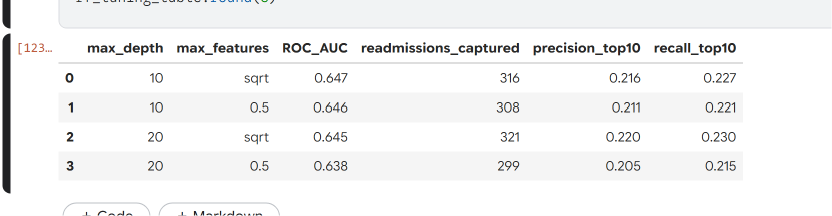

In [61]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=20,
    max_features="sqrt",
    random_state=13,
    n_jobs=-1
)

rf_model.fit(X_train_final, Y_train)
rf_val_proba = rf_model.predict_proba(X_val_final)[:, 1]

Next, I examine whether prediction errors differ by recorded gender.

# Prediction errors according to gender: The False-Negative Rate

Let's start with the logistic regression model.

In [62]:
log_val_results=pd.DataFrame(
    {
        "actual_readmission": Y_val,
        "predicted_probability": log_val_proba,
        "gender": validation.loc[Y_val.index, "gender"]
    },
    index=Y_val.index
)

# we create a new results table, adding the original 

In [63]:
n_flagged=round(len(log_val_results)*0.1)
log_flagged_index=log_val_results.nlargest(n_flagged, "predicted_probability").index
log_val_results["flagged"]=(
    log_val_results.index.isin(log_flagged_index)
).astype(int)
# we are creating a new column that says whether or not the encountere was flagged

log_val_results.head(20)

,actual_readmission,predicted_probability,gender,flagged
8,0,0.083591,Female,0
20,0,0.061665,Female,0
30,0,0.096260,Female,0
32,0,0.088037,Female,0
35,0,0.082255,Female,0
38,0,0.100382,Male,0
56,0,0.083545,Female,0
59,0,0.079034,Male,0
68,1,0.057682,Female,0
79,0,0.070824,Female,0


I double-check that the results for the model are still the same. 

In [64]:
print("Encounters flagged:", log_val_results["flagged"].sum())
print(
    "Readmissions captured:",
    log_val_results.loc[
        log_val_results["flagged"]==1,
        "actual_readmission"
    ].sum()
)

Encounters flagged: 1461
Readmissions captured: 305


I want to first get an overview of the gender proportions in the validation set before evaluating whether there is bias in the model's prediction.

In [65]:
log_gender_summary=log_val_results.groupby("gender").agg(
    encounters=("flagged","size"), # counts all the encounters
    flagged_encounters=("flagged", "sum"), # counts flagged encounters since 0/1
    selection_rate=("flagged","mean") # proportion flagged
)

log_gender_summary["selection_rate_pct"]=(
    log_gender_summary["selection_rate"]*100
)

log_gender_summary[["encounters", "flagged_encounters","selection_rate_pct"]
].round(2)

,encounters,flagged_encounters,selection_rate_pct
gender,,,
Female,7719,784,10.16
Male,6894,677,9.82


I decided to calculate the statistical parity difference, which tells me whether there's a gap in flagging rates between genders. However, this measures allocation rather than prediction errors. 

In [66]:
log_spd=(
    log_gender_summary.loc["Female","selection_rate"]-log_gender_summary.loc["Male","selection_rate"]
)

print(
    "Statistical parity difference (percentage points):",
    round(log_spd*100,2)
)

Statistical parity difference (percentage points): 0.34


This means that encounters are flagged 0.34 percentage points more often than male encounters.

Now let's calculate the false-negative rate: among actual early readmissions, what percentage did the model fail to flag?

In [67]:
log_readmitted=log_val_results.loc[log_val_results["actual_readmission"]==1].copy()
# counts the amount of people who were actual readmitted

log_error_summary=log_readmitted.groupby("gender").agg(
    actual_readmissions=("flagged","size"), # counts total amount of readmissions
    captured_readmissions=("flagged","sum") # counts amount of flagged readmissions
)

log_error_summary["missed_readmissions"]=(log_error_summary["actual_readmissions"]-log_error_summary["captured_readmissions"])
# calculates how many actual readmissions were not flagged

log_error_summary["false_negative_rate_pct"]=(log_error_summary["missed_readmissions"]/log_error_summary["actual_readmissions"]*100)
# calculates the false negative rate: among all actual readmissions, how many were not flagged?

log_error_summary.round(2)

,actual_readmissions,captured_readmissions,missed_readmissions,false_negative_rate_pct
gender,,,,
Female,706,156,550,77.90
Male,687,149,538,78.31


In [68]:
log_fn_gap=(
    log_error_summary.loc["Female", "false_negative_rate_pct"]
    - log_error_summary.loc["Male", "false_negative_rate_pct"]
)

print("False-negative rate gap (female minus male, in pp):", round(log_fn_gap, 2))

False-negative rate gap (female minus male, in pp): -0.41


On the validation set, the logistic regression's false-negative rate was 0.41 pp lower for female than male encounters. This suggests similar observed missed-readmission rates under the overall top 10% flagging rule. 

Let's calculate a 95% confidence interval for this gap.

In [69]:
bootstrap_data=log_val_results.copy()
bootstrap_data["patient_nbr"]=validation.loc[bootstrap_data.index,"patient_nbr"]
# we retrieve the patient number values from the validation dataset

for gender in ["Female","Male"]: # we assign the female and male variables into the set of variables "gender"
    actual=(
        (bootstrap_data["gender"]==gender)
        & (bootstrap_data["actual_readmission"]==1) 
    ) # we find the actually readmitted patients of a specific gender

    missed= actual&(bootstrap_data["flagged"]==0)
    # a missing readmission would be someone actually readmitted that didn't get flagged

    bootstrap_data[f"{gender}_actual"]=actual.astype(int)
    bootstrap_data[f"{gender}_missed"]=missed.astype(int)
    # we create two more columns to display our results

count_columns=["Female_actual","Female_missed","Male_actual","Male_missed"]
# creating a set of columns
patient_counts=bootstrap_data.groupby("patient_nbr")[count_columns].sum()
# in each column, how many patients are there

bootstrap_data.head()

,actual_readmission,predicted_probability,gender,flagged,patient_nbr,Female_actual,Female_missed,Male_actual,Male_missed
8,0,0.083591,Female,0,48330783,0,0,0,0
20,0,0.061665,Female,0,22864131,0,0,0,0
30,0,0.096260,Female,0,56480238,0,0,0,0
32,0,0.088037,Female,0,80845353,0,0,0,0
35,0,0.082255,Female,0,63023292,0,0,0,0


In [70]:
rng=np.random.default_rng(13) # random number generator, where 13 is the seed
counts=patient_counts.to_numpy() # converets table into number array (same order of values but withouot row and column labels)
n_patients=len(counts)

bootstrap_gaps=[]
for _ in range(2000): # resampple patient 2000 times
    sampled_positions=rng.integers(0, n_patients,size=n_patients)
    # generate random integers, starting at position 0, until total amount of patients - 1
    totals= counts[sampled_positions].sum(axis=0)
    female_actual, female_missed, male_actual, male_missed= totals
    if female_actual > 0 and male_actual > 0:
        gap=(female_missed/female_actual - male_missed/male_actual)*100
        bootstrap_gaps.append(gap)

lower, upper=np.percentile(bootstrap_gaps,[2.5,97.5])

print("95% confidence interval (in pp):", round(lower,2), "to", round(upper,2))

95% confidence interval (in pp): -6.76 to 5.57


The 95% CI for the false-negative rate is [-6.76, 5.57]. Since it includes 0, we can say that there there is, with 95% confidence, no difference in the prediction of errors between men and women with this logistic regression model. 

Now let's check if we encounter similar conclusions with the random forest model. 

In [71]:
rf_val_results=pd.DataFrame(
    {
        "actual_readmission": Y_val,
        "predicted_probability": rf_val_proba,
        "gender": validation.loc[Y_val.index, "gender"]
    },
    index=Y_val.index
)

n_flagged=round(len(rf_val_results)*0.1)
rf_flagged_index=rf_val_results.nlargest(n_flagged, "predicted_probability").index
rf_val_results["flagged"]=(
    rf_val_results.index.isin(rf_flagged_index)
).astype(int)

print("Encounters flagged:", rf_val_results["flagged"].sum())
print(
    "Readmissions captured:",
    rf_val_results.loc[
        rf_val_results["flagged"]==1,
        "actual_readmission"
    ].sum()
)

Encounters flagged: 1461
Readmissions captured: 321


In [72]:
rf_gender_summary=rf_val_results.groupby("gender").agg(
    encounters=("flagged","size"), 
    flagged_encounters=("flagged", "sum"), 
    selection_rate=("flagged","mean") 
)

rf_gender_summary["selection_rate_pct"]=(
    rf_gender_summary["selection_rate"]*100
)

rf_gender_summary[["encounters", "flagged_encounters","selection_rate_pct"]
].round(2)

rf_spd=(
    rf_gender_summary.loc["Female","selection_rate"]-rf_gender_summary.loc["Male","selection_rate"]
)

print(
    "Statistical parity difference (percentage points):",
    round(rf_spd*100,2)
)

Statistical parity difference (percentage points): 1.41


Note that the statistical parity difference is higher with random forest: it flags 1.6 pp more female encounters than male encounters. This is around 1.3 pp more than the SDP for logistic regression.

In [73]:
rf_readmitted=rf_val_results.loc[rf_val_results["actual_readmission"]==1].copy()

rf_error_summary=rf_readmitted.groupby("gender").agg(
    actual_readmissions=("flagged","size"),
    captured_readmissions=("flagged","sum")
)

rf_error_summary["missed_readmissions"]=(rf_error_summary["actual_readmissions"]-rf_error_summary["captured_readmissions"])
rf_error_summary["false_negative_rate_pct"]=(rf_error_summary["missed_readmissions"]/rf_error_summary["actual_readmissions"]*100)
rf_error_summary.round(2)

,actual_readmissions,captured_readmissions,missed_readmissions,false_negative_rate_pct
gender,,,,
Female,706,170,536,75.92
Male,687,151,536,78.02


In [74]:
rf_fn_gap=(
    rf_error_summary.loc["Female", "false_negative_rate_pct"]
    - rf_error_summary.loc["Male", "false_negative_rate_pct"]
)

print("False-negative rate gap (female minus male, in pp):", round(rf_fn_gap, 2))

False-negative rate gap (female minus male, in pp): -2.1


Unlike with the logistic regression model, I find a negative false-negative rate for the random forest model. This means that actual readmissions were missed more often among male encounters in this case.

In [75]:
bootstrap_data_1=rf_val_results.copy()
bootstrap_data_1["patient_nbr"]=validation.loc[bootstrap_data_1.index,"patient_nbr"]

for gender in ["Female","Male"]: 
    actual=(
        (bootstrap_data_1["gender"]==gender)
        & (bootstrap_data_1["actual_readmission"]==1) 
    ) # we find the actually readmitted patients of a specific gender

    missed= actual&(bootstrap_data_1["flagged"]==0)
    # a missing readmission would be someone actually readmitted that didn't get flagged

    bootstrap_data_1[f"{gender}_actual"]=actual.astype(int)
    bootstrap_data_1[f"{gender}_missed"]=missed.astype(int)
    # we create two more columns to display our results

count_columns=["Female_actual","Female_missed","Male_actual","Male_missed"]
patient_counts=bootstrap_data_1.groupby("patient_nbr")[count_columns].sum()

rng=np.random.default_rng(13) # random number generator, where 13 is the seed
counts=patient_counts.to_numpy() # converets table into number array (same order of values but withouot row and column labels)
n_patients=len(counts)

bootstrap_gaps=[]
for _ in range(2000): 
    sampled_positions=rng.integers(0, n_patients,size=n_patients)
    totals= counts[sampled_positions].sum(axis=0)
    female_actual, female_missed, male_actual, male_missed= totals
    if female_actual > 0 and male_actual > 0:
        gap=(female_missed/female_actual - male_missed/male_actual)*100
        bootstrap_gaps.append(gap)

lower, upper=np.percentile(bootstrap_gaps,[2.5,97.5])

print("95% confidence interval (in pp):", round(lower,2), "to", round(upper,2))

95% confidence interval (in pp): -8.71 to 4.12


However, this result does not seem to be significant at 5% level, as the confidence interval for the false-negative rate gap is [-9.45, 3.31]. 

# Prediction errors according to gender: The False-Positive Rate

Now the question is: among encounters that did not result in early readmission, what proportion did the models flag?

In [76]:
log_not_readmitted=log_val_results.loc[log_val_results["actual_readmission"]==0].copy()
# we locate the rows whose encounters were not readmitted early
log_fp_summary=log_not_readmitted.groupby("gender").agg(
    actual_non_readmissions=("flagged","size"),
    false_positives=("flagged","sum")
)

log_fp_summary["false_positive_rate_pct"]=(log_fp_summary["false_positives"]/log_fp_summary["actual_non_readmissions"]*100)
log_fp_summary.round(2)

,actual_non_readmissions,false_positives,false_positive_rate_pct
gender,,,
Female,7013,628,8.95
Male,6207,528,8.51


In [77]:
log_fp_gap=(log_fp_summary.loc["Female", "false_positive_rate_pct"]-log_fp_summary.loc["Male", "false_positive_rate_pct"])
print("False-positive rate gap (female minus male, in pp):", round(log_fp_gap,2))

False-positive rate gap (female minus male, in pp): 0.45


In [78]:
bootstrap_data_2=log_val_results.copy()
bootstrap_data_2["patient_nbr"]=validation.loc[bootstrap_data_2.index,"patient_nbr"]

for gender in ["Female","Male"]:  
    not_actual=(
        (bootstrap_data_2["gender"]==gender)
        & (bootstrap_data_2["actual_readmission"]==0) 
    ) 

    false_positives= not_actual&(bootstrap_data_2["flagged"]==1)

    bootstrap_data_2[f"{gender}_not_readmitted"]=not_actual.astype(int)
    bootstrap_data_2[f"{gender}_false_positive"]=false_positives.astype(int)

count_columns=["Female_not_readmitted","Female_false_positive","Male_not_readmitted","Male_false_positive"]
patient_counts=bootstrap_data_2.groupby("patient_nbr")[count_columns].sum()

rng=np.random.default_rng(13) 
counts=patient_counts.to_numpy() 
n_patients=len(counts)

bootstrap_gaps=[]
for _ in range(2000): 
    sampled_positions=rng.integers(0, n_patients,size=n_patients)
    totals= counts[sampled_positions].sum(axis=0)
    female_not_actual, female_fp, male_not_actual, male_fp= totals
    if female_not_actual > 0 and male_not_actual > 0:
        gap=(female_fp/female_not_actual - male_fp/male_not_actual)*100
        bootstrap_gaps.append(gap)

lower, upper=np.percentile(bootstrap_gaps,[2.5,97.5])

print("95% confidence interval (in pp):", round(lower,2), "to", round(upper,2))

95% confidence interval (in pp): -0.87 to 1.81


In [79]:
rf_not_readmitted=rf_val_results.loc[rf_val_results["actual_readmission"]==0].copy()
rf_fp_summary=rf_not_readmitted.groupby("gender").agg(
    actual_non_readmissions=("flagged","size"),
    false_positives=("flagged","sum")
)

rf_fp_summary["false_positive_rate_pct"]=(rf_fp_summary["false_positives"]/rf_fp_summary["actual_non_readmissions"]*100)
rf_fp_summary.round(2)

,actual_non_readmissions,false_positives,false_positive_rate_pct
gender,,,
Female,7013,653,9.31
Male,6207,487,7.85


In [80]:
rf_fp_gap=(rf_fp_summary.loc["Female", "false_positive_rate_pct"]-rf_fp_summary.loc["Male", "false_positive_rate_pct"])
print("False-positive rate gap (female minus male, in pp):", round(rf_fp_gap,2))

False-positive rate gap (female minus male, in pp): 1.47


In [81]:
bootstrap_data_3=rf_val_results.copy()
bootstrap_data_3["patient_nbr"]=validation.loc[bootstrap_data_3.index,"patient_nbr"]

for gender in ["Female","Male"]: 
    not_actual=(
        (bootstrap_data_3["gender"]==gender)
        & (bootstrap_data_3["actual_readmission"]==0) 
    ) 

    false_positives= not_actual&(bootstrap_data_3["flagged"]==1)

    bootstrap_data_3[f"{gender}_not_readmitted"]=not_actual.astype(int)
    bootstrap_data_3[f"{gender}_false_positive"]=false_positives.astype(int)

count_columns=["Female_not_readmitted","Female_false_positive","Male_not_readmitted","Male_false_positive"]
patient_counts=bootstrap_data_3.groupby("patient_nbr")[count_columns].sum()

rng=np.random.default_rng(13) 
counts=patient_counts.to_numpy() 
n_patients=len(counts)

bootstrap_gaps=[]
for _ in range(2000): 
    sampled_positions=rng.integers(0, n_patients,size=n_patients)
    totals= counts[sampled_positions].sum(axis=0)
    female_not_actual, female_fp, male_not_actual, male_fp= totals
    if female_not_actual > 0 and male_not_actual > 0:
        gap=(female_fp/female_not_actual - male_fp/male_not_actual)*100
        bootstrap_gaps.append(gap)

lower, upper=np.percentile(bootstrap_gaps,[2.5,97.5])

print("95% confidence interval (in pp):", round(lower,2), "to", round(upper,2))

95% confidence interval (in pp): 0.09 to 2.79


I find that the false-positive rate gap is positive for both models, although this gap is only significant in the logistic regression model.

# Conclusions on prediction errors according to gender on the validation set

For missed readmissions, there’s considerable uncertainty. For example, the forest’s interval is compatible with a female false-negative rate 9.45 pp lower or 3.31 pp higher than the male rate. Therefore, I cannot conclude that missed-readmission rates are equal or confidently establish the direction of the difference.

For false positives, the estimates are more precise. The forest’s entire interval is above zero: female encounters that did not result in early readmission were flagged more often. The estimated difference is 16 additional flags per 1,000 non-readmission encounters, with an interval corresponding to approximately 2–29 additional flags per 1,000.

The narrower false-positive intervals can be explained by the fact that there are 13,220 non-readmission encounters, compared with only 1,393 readmission encounters informing the false-negative comparisons.

# Check persistence of results with test set

Let's do one model at a time, starting with the logistic regression model once more. 

In [82]:
X_test = test[features].copy()
Y_test = test["readmitted_30"].copy()

test_num_scaled=scaler.transform(
    X_test[numeric_features]
)

test_num_scaled = pd.DataFrame( 
    test_num_scaled, 
    columns=numeric_features, 
    index=X_test.index 
)

test_cat_encoded=encoder.transform(
    X_test[categorical_features]
)

test_cat_encoded=pd.DataFrame(
    test_cat_encoded,
    columns=encoder.get_feature_names_out(categorical_features), 
    index=X_test.index  
)

X_test_final=pd.concat( 
    [test_num_scaled, test_cat_encoded],
    axis=1 
)

print("Shape:", X_test_final.shape)
print("Missing values:", X_test_final.isna().sum().sum())
print("Rows match outcome:",X_test_final.index.equals(Y_test.index))

Shape: (14541, 62)
Missing values: 0
Rows match outcome: True


In [83]:
log_test_proba = logistic_model.predict_proba(X_test_final)[:,1]

log_test_results=pd.DataFrame(
    {
        "actual_readmission": Y_test,
        "predicted_probability": log_test_proba
    },
    index=X_test_final.index
)

log_test_results.head()

,actual_readmission,predicted_probability
1,0,0.063006
5,0,0.075594
6,0,0.069875
10,0,0.092940
16,1,0.069484


In [84]:
log_test_results.groupby("actual_readmission")["predicted_probability"].agg(["count","mean","median"])

,count,mean,median
actual_readmission,,,
0,13143,0.096117,0.083567
1,1398,0.133795,0.103595


In [85]:
log_test_auc=roc_auc_score(Y_test, log_test_proba)
print("Test ROC AUC LR model:", round(log_test_auc,3))

Test ROC AUC LR model: 0.657


In [86]:
n_test_flagged=round(len(log_test_results)*0.1)
log_top_10=log_test_results.nlargest(n_test_flagged, "predicted_probability")



log_readmissions_captured=log_top_10["actual_readmission"].sum()
log_precision=log_readmissions_captured/len(log_top_10)
log_recall =(
    log_readmissions_captured/log_test_results["actual_readmission"].sum()
)

print("Encounters flagged:", len(log_top_10))
print("Readmissions captured:", log_readmissions_captured)
print("Precision (%):", round(log_precision*100,2))
print("Recall (%):", round(log_recall*100,2))

Encounters flagged: 1454
Readmissions captured: 327
Precision (%): 22.49
Recall (%): 23.39


In [87]:
log_test_results=pd.DataFrame(
    {
        "actual_readmission": Y_test,
        "predicted_probability": log_test_proba,
        "gender": test.loc[Y_test.index, "gender"]
    },
    index=Y_test.index
)

n_test_flagged=round(len(log_test_results)*0.1)
log_flagged_index=log_test_results.nlargest(n_test_flagged, "predicted_probability").index
log_test_results["flagged"]=(
    log_test_results.index.isin(log_flagged_index)
).astype(int)

print("Encounters flagged:", log_test_results["flagged"].sum())
print(
    "Readmissions captured:",
    log_test_results.loc[
        log_test_results["flagged"]==1,
        "actual_readmission"
    ].sum()
)

log_readmitted=log_test_results.loc[log_test_results["actual_readmission"]==1].copy()

log_error_summary=log_readmitted.groupby("gender").agg(
    actual_readmissions=("flagged","size"), 
    captured_readmissions=("flagged","sum") 
)

log_error_summary["missed_readmissions"]=(log_error_summary["actual_readmissions"]-log_error_summary["captured_readmissions"])

log_error_summary["false_negative_rate_pct"]=(log_error_summary["missed_readmissions"]/log_error_summary["actual_readmissions"]*100)

log_error_summary.round(2)

Encounters flagged: 1454
Readmissions captured: 327


,actual_readmissions,captured_readmissions,missed_readmissions,false_negative_rate_pct
gender,,,,
Female,738,182,556,75.34
Male,660,145,515,78.03


In [88]:
log_fn_gap=(
    log_error_summary.loc["Female", "false_negative_rate_pct"]
    - log_error_summary.loc["Male", "false_negative_rate_pct"]
)

print("False-negative rate gap (female minus male, in pp):", round(log_fn_gap, 2))

False-negative rate gap (female minus male, in pp): -2.69


In [89]:
bootstrap_test_log=log_test_results.copy()
bootstrap_test_log["patient_nbr"]=test.loc[bootstrap_test_log.index,"patient_nbr"]

for gender in ["Female","Male"]: 
    actual=(
        (bootstrap_test_log["gender"]==gender)
        & (bootstrap_test_log["actual_readmission"]==1) 
    ) 

    missed= actual&(bootstrap_test_log["flagged"]==0)

    bootstrap_test_log[f"{gender}_actual"]=actual.astype(int)
    bootstrap_test_log[f"{gender}_missed"]=missed.astype(int)

count_columns=["Female_actual","Female_missed","Male_actual","Male_missed"]
patient_counts=bootstrap_test_log.groupby("patient_nbr")[count_columns].sum()

rng=np.random.default_rng(13)
counts=patient_counts.to_numpy() 
n_patients=len(counts)

bootstrap_gaps=[]
for _ in range(2000): 
    sampled_positions=rng.integers(0, n_patients,size=n_patients)
    totals= counts[sampled_positions].sum(axis=0)
    female_actual, female_missed, male_actual, male_missed= totals
    if female_actual > 0 and male_actual > 0:
        gap=(female_missed/female_actual - male_missed/male_actual)*100
        bootstrap_gaps.append(gap)

lower, upper=np.percentile(bootstrap_gaps,[2.5,97.5])

print("95% confidence interval (in pp):", round(lower,2), "to", round(upper,2))

95% confidence interval (in pp): -8.94 to 3.55


In [90]:
log_not_readmitted=log_test_results.loc[log_test_results["actual_readmission"]==0].copy()
log_fp_summary=log_not_readmitted.groupby("gender").agg(
    actual_non_readmissions=("flagged","size"),
    false_positives=("flagged","sum")
)

log_fp_summary["false_positive_rate_pct"]=(log_fp_summary["false_positives"]/log_fp_summary["actual_non_readmissions"]*100)
log_fp_summary.round(2)

,actual_non_readmissions,false_positives,false_positive_rate_pct
gender,,,
Female,6859,607,8.85
Male,6284,520,8.27


In [91]:
log_fp_gap=(log_fp_summary.loc["Female", "false_positive_rate_pct"]-log_fp_summary.loc["Male", "false_positive_rate_pct"])
print("False-positive rate gap (female minus male, in pp):", round(log_fp_gap,2))

False-positive rate gap (female minus male, in pp): 0.57


In [92]:
bootstrap_test_log_1=log_test_results.copy()
bootstrap_test_log_1["patient_nbr"]=test.loc[bootstrap_test_log_1.index,"patient_nbr"]

for gender in ["Female","Male"]:  
    not_actual=(
        (bootstrap_test_log_1["gender"]==gender)
        & (bootstrap_test_log_1["actual_readmission"]==0) 
    ) 

    false_positives= not_actual&(bootstrap_test_log_1["flagged"]==1)

    bootstrap_test_log_1[f"{gender}_not_readmitted"]=not_actual.astype(int)
    bootstrap_test_log_1[f"{gender}_false_positive"]=false_positives.astype(int)

count_columns=["Female_not_readmitted","Female_false_positive","Male_not_readmitted","Male_false_positive"]
patient_counts=bootstrap_test_log_1.groupby("patient_nbr")[count_columns].sum()

rng=np.random.default_rng(13) 
counts=patient_counts.to_numpy() 
n_patients=len(counts)

bootstrap_gaps=[]
for _ in range(2000): 
    sampled_positions=rng.integers(0, n_patients,size=n_patients)
    totals= counts[sampled_positions].sum(axis=0)
    female_not_actual, female_fp, male_not_actual, male_fp= totals
    if female_not_actual > 0 and male_not_actual > 0:
        gap=(female_fp/female_not_actual - male_fp/male_not_actual)*100
        bootstrap_gaps.append(gap)

lower, upper=np.percentile(bootstrap_gaps,[2.5,97.5])

print("95% confidence interval (in pp):", round(lower,2), "to", round(upper,2))

95% confidence interval (in pp): -0.8 to 1.87


On the held-out test set, logistic regression showed modest predictive performance (ROC AUC = 0.657). Flagging the highest-risk 10% of encounters captured 23.29% of early readmissions, with a precision of 22.49%. This suggests the model could help prioritise follow-up, although it missed approximately three-quarters of early readmissions. The female-minus-male gaps were −2.69 percentage points for the false-negative rate (95% CI: -8.94 to 3.55) and +0.57 percentage points for the false-positive rate (95% CI: −0.8 to 1.87). Both confidence intervals included zero, so the analysis did not provide clear evidence of gender differences in these error rates; however, this does not establish that the model performs equally across genders.

Now, let's check out what's going on with the random forest model.

In [93]:
rf_test_proba=rf_model.predict_proba(X_test_final)[:,1]
rf_test_results=pd.DataFrame(
    {
        "actual_readmission": Y_test,
        "predicted_probability": rf_test_proba
    },
    index=Y_test.index
)

rf_test_results.head()

,actual_readmission,predicted_probability
1,0,0.090015
5,0,0.079722
6,0,0.093728
10,0,0.115774
16,1,0.074942


In [94]:
rf_test_results=pd.DataFrame(
    {
        "actual_readmission": Y_test,
        "predicted_probability": rf_test_proba,
        "gender": test.loc[Y_test.index, "gender"]
    },
    index=Y_test.index
)

n_test_flagged=round(len(rf_test_results)*0.1)
rf_flagged_index=rf_test_results.nlargest(n_test_flagged, "predicted_probability").index
rf_test_results["flagged"]=(
    rf_test_results.index.isin(rf_flagged_index)
).astype(int)

rf_auc=roc_auc_score(Y_test, rf_test_proba)

rf_top_10=rf_test_results.nlargest(n_test_flagged, "predicted_probability")
rf_readmissions_captured=rf_top_10["actual_readmission"].sum()
rf_precision=rf_readmissions_captured/len(rf_top_10)
rf_recall =(
    rf_readmissions_captured/rf_test_results["actual_readmission"].sum()
)

print("Encounters flagged:", len(rf_top_10))
print("Readmissions captured:", rf_readmissions_captured)
print("Precision (%):", round(rf_precision*100,2))
print("Recall (%):", round(rf_recall*100,2))
print("Test ROC AUC RF model:", round(rf_auc,3))

Encounters flagged: 1454
Readmissions captured: 333
Precision (%): 22.9
Recall (%): 23.82
Test ROC AUC RF model: 0.659


In [95]:
rf_test_results.groupby("actual_readmission")["predicted_probability"].agg(["count","mean","median"])

,count,mean,median
actual_readmission,,,
0,13143,0.097424,0.086540
1,1398,0.128006,0.110234


In [96]:
rf_test_results=pd.DataFrame(
    {
        "actual_readmission": Y_test,
        "predicted_probability": rf_test_proba,
        "gender": test.loc[Y_test.index, "gender"]
    },
    index=Y_test.index
)

n_test_flagged=round(len(rf_test_results)*0.1)
rf_flagged_index=rf_test_results.nlargest(n_test_flagged, "predicted_probability").index
rf_test_results["flagged"]=(
    rf_test_results.index.isin(rf_flagged_index)
).astype(int)

rf_readmitted=rf_test_results.loc[rf_test_results["actual_readmission"]==1].copy()

rf_error_summary=rf_readmitted.groupby("gender").agg(
    actual_readmissions=("flagged","size"), 
    captured_readmissions=("flagged","sum") 
)

rf_error_summary["missed_readmissions"]=(rf_error_summary["actual_readmissions"]-rf_error_summary["captured_readmissions"])
rf_error_summary["false_negative_rate_pct"]=(rf_error_summary["missed_readmissions"]/rf_error_summary["actual_readmissions"]*100)

rf_error_summary.round(2)

,actual_readmissions,captured_readmissions,missed_readmissions,false_negative_rate_pct
gender,,,,
Female,738,199,539,73.04
Male,660,134,526,79.70


In [97]:
rf_fn_gap=(
    rf_error_summary.loc["Female", "false_negative_rate_pct"]
    - rf_error_summary.loc["Male", "false_negative_rate_pct"]
)

print("False-negative rate gap (female minus male, in pp):", round(rf_fn_gap, 2))

False-negative rate gap (female minus male, in pp): -6.66


In [98]:
bootstrap_test_rf=rf_test_results.copy()
bootstrap_test_rf["patient_nbr"]=test.loc[bootstrap_test_rf.index,"patient_nbr"]

for gender in ["Female","Male"]: 
    actual=(
        (bootstrap_test_rf["gender"]==gender)
        & (bootstrap_test_rf["actual_readmission"]==1) 
    ) 

    missed= actual&(bootstrap_test_rf["flagged"]==0)

    bootstrap_test_rf[f"{gender}_actual"]=actual.astype(int)
    bootstrap_test_rf[f"{gender}_missed"]=missed.astype(int)

count_columns=["Female_actual","Female_missed","Male_actual","Male_missed"]
patient_counts=bootstrap_test_rf.groupby("patient_nbr")[count_columns].sum()

rng=np.random.default_rng(13) 
counts=patient_counts.to_numpy()  
n_patients=len(counts)

bootstrap_gaps=[]
for _ in range(2000): 
    sampled_positions=rng.integers(0, n_patients,size=n_patients)
    totals= counts[sampled_positions].sum(axis=0)
    female_actual, female_missed, male_actual, male_missed= totals
    if female_actual > 0 and male_actual > 0:
        gap=(female_missed/female_actual - male_missed/male_actual)*100
        bootstrap_gaps.append(gap)

lower, upper=np.percentile(bootstrap_gaps,[2.5,97.5])

print("95% confidence interval (in pp):", round(lower,2), "to", round(upper,2))

95% confidence interval (in pp): -12.87 to -0.41


In [99]:
rf_not_readmitted=rf_test_results.loc[rf_test_results["actual_readmission"]==0].copy()
rf_fp_summary=rf_not_readmitted.groupby("gender").agg(
    actual_non_readmissions=("flagged","size"),
    false_positives=("flagged","sum")
)

rf_fp_summary["false_positive_rate_pct"]=(rf_fp_summary["false_positives"]/rf_fp_summary["actual_non_readmissions"]*100)
rf_fp_summary.round(2)

,actual_non_readmissions,false_positives,false_positive_rate_pct
gender,,,
Female,6859,618,9.01
Male,6284,503,8.00


In [100]:
rf_fp_gap=(rf_fp_summary.loc["Female", "false_positive_rate_pct"]-rf_fp_summary.loc["Male", "false_positive_rate_pct"])
print("False-positive rate gap (female minus male, in pp):", round(rf_fp_gap,2))

False-positive rate gap (female minus male, in pp): 1.01


In [101]:
bootstrap_test_rf_1=rf_test_results.copy()
bootstrap_test_rf_1["patient_nbr"]=test.loc[bootstrap_test_rf_1.index,"patient_nbr"]

for gender in ["Female","Male"]: 
    not_actual=(
        (bootstrap_test_rf_1["gender"]==gender)
        & (bootstrap_test_rf_1["actual_readmission"]==0) 
    ) 

    false_positives= not_actual&(bootstrap_test_rf_1["flagged"]==1)

    bootstrap_test_rf_1[f"{gender}_not_readmitted"]=not_actual.astype(int)
    bootstrap_test_rf_1[f"{gender}_false_positive"]=false_positives.astype(int)

count_columns=["Female_not_readmitted","Female_false_positive","Male_not_readmitted","Male_false_positive"]
patient_counts=bootstrap_test_rf_1.groupby("patient_nbr")[count_columns].sum()

rng=np.random.default_rng(13) 
counts=patient_counts.to_numpy() 
n_patients=len(counts)

bootstrap_gaps=[]
for _ in range(2000): 
    sampled_positions=rng.integers(0, n_patients,size=n_patients)
    totals= counts[sampled_positions].sum(axis=0)
    female_not_actual, female_fp, male_not_actual, male_fp= totals
    if female_not_actual > 0 and male_not_actual > 0:
        gap=(female_fp/female_not_actual - male_fp/male_not_actual)*100
        bootstrap_gaps.append(gap)

lower, upper=np.percentile(bootstrap_gaps,[2.5,97.5])

print("95% confidence interval (in pp):", round(lower,2), "to", round(upper,2))

95% confidence interval (in pp): -0.41 to 2.38


On the test set, the random forest showed modest predictive performance (ROC AUC = 0.659). Flagging the highest-risk 10% of encounters captured 333 early readmissions, corresponding to a recall of 23.82% and precision of 22.90%. This is only a small improvement over logistic regression. I found that the false-negative rate was 6.66 percentage points lower for female than male encounters (95% CI: −12.87 to −0.41), suggesting that actual early readmissions were missed more often among male encounters. The false-positive rate gap was +1.01 percentage points (95% CI: −0.41 to 2.38), providing no clear evidence of a difference.

These exploratory findings show that similar overall predictive performance can coexist with differences in how errors are distributed across groups.